## Importamos las librerias necesarias

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Cargamos el dataset

In [31]:
df= pd.read_csv("bank_subscription.csv",delimiter=";")
df.head()


,Age,Job,Marital Status,Education,Credit,Balance (euros),Housing Loan,Personal Loan,Contact,Last Contact Day,Last Contact Month,Last Contact Duration,Campaign,Pdays,Previous,Poutcome,Subscription
0,58.0,NaN,NaN,NaN,no,2143.0,yes,NaN,unknown,5,may,261.0,1,-1.0,0,unknown,0
1,44.0,technician,single,secondary,no,NaN,yes,no,unknown,5,may,151.0,1,-1.0,0,unknown,0
2,33.0,entrepreneur,NaN,secondary,no,2.0,yes,yes,unknown,5,may,76.0,1,NaN,0,unknown,0
3,47.0,NaN,married,unknown,no,1506.0,NaN,no,unknown,5,may,92.0,1,-1.0,0,unknown,0
4,33.0,unknown,single,unknown,NaN,1.0,no,no,unknown,5,may,NaN,1,NaN,0,unknown,0


## Determinamos la cantidad de filas y columnas

In [32]:
filas = np.shape(df)[0]
columnas = np.shape(df)[1]
print(f"Filas: {filas}")
print(f"Columnas: {columnas}")
nombre_col= df.columns.values
nombre_col

Filas: 45211
Columnas: 17


<ArrowStringArray>
[                  'Age',                   'Job',        'Marital Status',
             'Education',                'Credit',       'Balance (euros)',
          'Housing Loan',         'Personal Loan',               'Contact',
      'Last Contact Day',    'Last Contact Month', 'Last Contact Duration',
              'Campaign',                 'Pdays',              'Previous',
              'Poutcome',          'Subscription']
Length: 17, dtype: str

## Chequeamos nulos

In [33]:
df.isnull().sum()

Age                      4973
Job                      4973
Marital Status           4973
Education                4973
Credit                   4973
Balance (euros)          4973
Housing Loan             7686
Personal Loan            7686
Contact                     0
Last Contact Day            0
Last Contact Month          0
Last Contact Duration    7686
Campaign                    0
Pdays                    7686
Previous                    0
Poutcome                    0
Subscription                0
dtype: int64

*Vemos que hay 6 columnas con ~10% de nulos y otras cuatro con ~17%. Queda pendiente definir una estrategia de imputacion. Para definirla, hacemos un breve análisis sobre la distribución de cada variable*

In [34]:
for col in df.columns:
    print(f"{col} ({df[col].nunique(dropna=False)} valores únicos)")
    print(df[col].unique())
    print("-" * 40)

Age (78 valores únicos)
[58. 44. 33. 47. 35. 28. 42. 43. 41. 29. 53. 57. 51. 45. 60. 56. 32. 25.
 40. nan 52. 36. 49. 59. 37. 50. 54. 55. 48. 24. 38. 46. 30. 39. 34. 31.
 23. 26. 61. 22. 27. 21. 20. 66. 62. 83. 75. 67. 70. 65. 68. 64. 72. 71.
 19. 76. 69. 85. 63. 90. 82. 73. 74. 78. 80. 94. 79. 77. 95. 81. 18. 89.
 84. 86. 87. 92. 93. 88.]
----------------------------------------
Job (13 valores únicos)
<ArrowStringArray>
[            nan,    'technician',  'entrepreneur',       'unknown',
    'management',       'retired',        'admin.',      'services',
   'blue-collar', 'self-employed',    'unemployed',     'housemaid',
       'student']
Length: 13, dtype: str
----------------------------------------
Marital Status (4 valores únicos)
<ArrowStringArray>
[nan, 'single', 'married', 'divorced']
Length: 4, dtype: str
----------------------------------------
Education (5 valores únicos)
<ArrowStringArray>
[nan, 'secondary', 'unknown', 'tertiary', 'primary']
Length: 5, dtype: str
-------

 Notamos que: <br>
Age es numérica. En función de la dispersión, convendrá imputar con media, mediana o moda.<br>
Job es categórica. Una de sus categorías es "unknown", se le asigna ese valor a los nulos.<br>
Marital status es categórica con solo tres variables.<br>
Education es categórica y también contempla una categoría unknown.<br>
Credit es binaria.<br>
Balance es continua, misma conclusión que Age.<br>
Housing y Personal Loan son binarias.<br>
Last Contact Duration y Pdays son continuas<br>

Tomamos las binarias (más Marital Status que es categórica con tres variables) y hacemos un Count Plot para ver como se distribuyen los valores

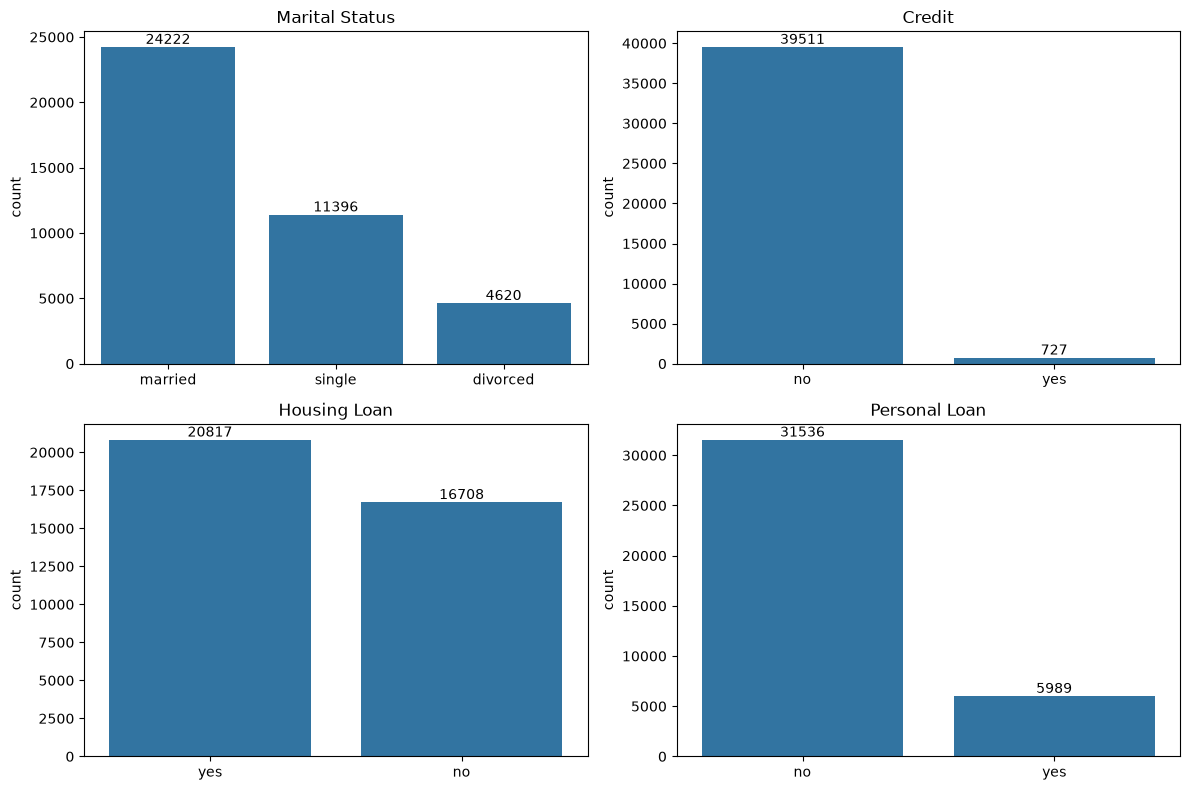

In [39]:
cols = ["Marital Status", "Credit", "Housing Loan", "Personal Loan"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flatten(), cols):
    sns.countplot(data=df, x=col, ax=ax, order=df[col].value_counts().index)
    ax.set_title(col)
    ax.set_xlabel("")
    for container in ax.containers:
        ax.bar_label(container)

plt.tight_layout()
plt.show()

**Variables binarias y categóricas: estrategia de imputación**

**Credit y Personal Loan:** en ambas variables, la gran mayoría de los registros corresponde a "no". Ante esta distribución tan desbalanceada, imputamos los valores faltantes con la moda, ya que es la opción con mayor probabilidad de acierto.

**Housing Loan:** la distribución entre "yes" y "no" es prácticamente equilibrada, por lo que imputar con la moda introduciría un error considerable. Optamos por agrupar los faltantes en una nueva categoría, `unknown`.

**Marital Status:** si bien la categoría dominante no es tan marcada como en Credit o Personal Loan, "married" sigue siendo claramente la más frecuente. Por eso, también imputamos con la moda.

In [41]:
# Moda: Credit, Personal Loan, Marital Status
for col in ["Credit", "Personal Loan", "Marital Status"]:
    df[col] = df[col].fillna(df[col].mode()[0])

# Categoría unknown: Housing Loan, Job, Education
for col in ["Housing Loan", "Job", "Education"]:
    df[col] = df[col].fillna("unknown")

# Verificación
df[["Credit", "Personal Loan", "Marital Status", "Housing Loan", "Job", "Education"]].isnull().sum()

Credit            0
Personal Loan     0
Marital Status    0
Housing Loan      0
Job               0
Education         0
dtype: int64

Para determinar la estrategia de imputación de variables continuas, hacemos un boxplot para determinar la dispersión de su distribución

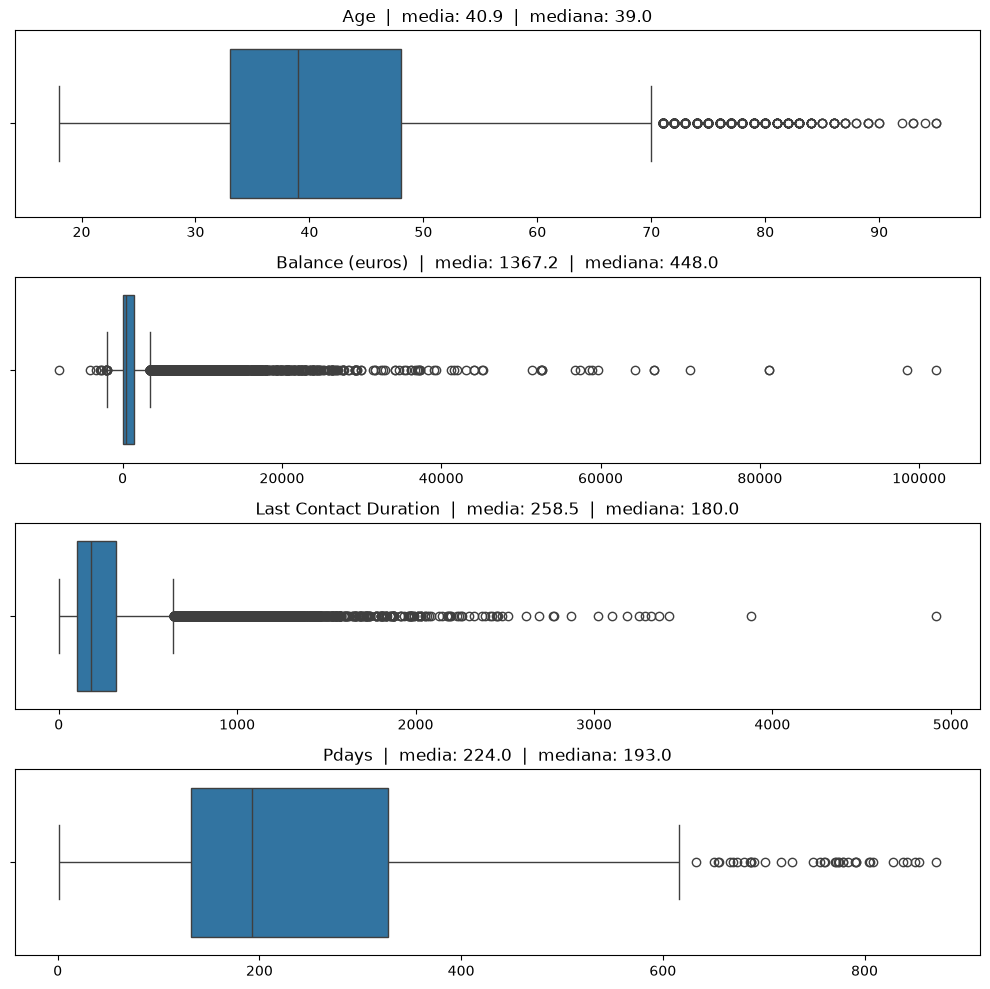

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

continuas_nulos = ["Age", "Balance (euros)", "Last Contact Duration", "Pdays"]

fig, axes = plt.subplots(len(continuas_nulos), 1, figsize=(10, 2.5 * len(continuas_nulos)))

for ax, col in zip(axes, continuas_nulos):
    datos = df.loc[df["Pdays"] != -1, col] if col == "Pdays" else df[col]
    sns.boxplot(x=datos, ax=ax)
    ax.set_title(f"{col}  |  media: {datos.mean():.1f}  |  mediana: {datos.median():.1f}")
    ax.set_xlabel("")

plt.tight_layout()
plt.show()

**Variables continuas: estrategia de imputación**

**Age y Balance (euros):** ambas distribuciones presentan colas largas hacia la derecha y una cantidad considerable de outliers, especialmente Balance, cuya media casi triplica a la mediana. Para evitar que los valores extremos distorsionen la imputación, completamos los faltantes con la mediana, que es robusta ante este tipo de distribuciones.

**Pdays:** en esta variable, el valor `-1` indica que el cliente no fue contactado en campañas anteriores, por lo que la imputación debe respetar ese significado. Aplicamos dos criterios:
- Si `Previous` es 0, el cliente nunca fue contactado, por lo que imputamos `-1`.
- En el resto de los casos, imputamos con la mediana de Pdays calculada solo sobre los clientes contactados previamente (excluyendo los `-1`).